# Unsupervised NN (Autoencoder) for Anomaly-Based NIDS

This trains an **autoencoder** on the same flow-feature schema as your supervised MLP, but unsupervised: it only ever sees `BENIGN` traffic during training. It learns to reconstruct normal traffic well; anything it reconstructs *poorly* (high reconstruction error) is flagged as anomalous - including attack types your supervised model was never trained on.

Reuses the same `BASE_PATH`, cleaning steps, and train/test split logic as `nids_mlp_pipeline.ipynb` so the two models stay consistent, but trains its own separate scaler (fit only on benign rows) to avoid contaminating the autoencoder's notion of "normal" with attack traffic statistics.

## Step 0: Imports & Setup

In [1]:
import os
import numpy as np
import pandas as pd
import joblib

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, classification_report,
    roc_auc_score, roc_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

print(f"Tensorflow Version: {tf.__version__}")


Tensorflow Version: 2.10.0


## Step 1: Load & Clean Data
Same as the supervised pipeline: combine CSVs, strip column names, replace inf with NaN, median-impute.

In [2]:
BASE_PATH = "./data/cicids2017"  # <-- match your supervised pipeline's path

csv_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".csv")]
print(f"Found {len(csv_files)} CSV files.")

dfs = [pd.read_csv(os.path.join(BASE_PATH, f), encoding="utf-8") for f in csv_files]
df = pd.concat(dfs, ignore_index=True)

df.columns = df.columns.str.strip()
label_col = "Label"

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print(f"Total dataset shape: {df.shape}")
print(df[label_col].value_counts())


Found 8 CSV files.
Total dataset shape: (2830743, 79)
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


## Step 2: Split — Benign-Only Training Set
The key difference from the supervised pipeline: the autoencoder's training set is **benign traffic only**. Attack rows are held out entirely from training and only used at evaluation time, mixed back in with a benign test set to check the model correctly flags them as anomalies.

In [3]:
X = df.drop(columns=[label_col], errors="ignore").select_dtypes(include=[np.number])
y_raw = df[label_col].copy()
feature_names = X.columns.tolist()

is_benign = y_raw.str.upper() == "BENIGN"
X_benign = X[is_benign]
X_attack = X[~is_benign]
y_attack_labels = y_raw[~is_benign]

print(f"Benign rows: {len(X_benign):,} | Attack rows: {len(X_attack):,}")

# Split benign data: most goes to training, a held-out slice goes to the test set
X_benign_train, X_benign_test = train_test_split(
    X_benign, test_size=0.3, random_state=42
)

print(f"Benign train: {len(X_benign_train):,} | Benign test: {len(X_benign_test):,} | Attack (all held out): {len(X_attack):,}")


Benign rows: 2,273,097 | Attack rows: 557,646
Benign train: 1,591,167 | Benign test: 681,930 | Attack (all held out): 557,646


## Step 3: Scale
A separate scaler from the supervised pipeline, fit **only on benign training rows** — this keeps the autoencoder's definition of "normal" uncontaminated by attack statistics.

In [4]:
ae_scaler = StandardScaler()
X_benign_train_scaled = ae_scaler.fit_transform(X_benign_train)
X_benign_test_scaled = ae_scaler.transform(X_benign_test)
X_attack_scaled = ae_scaler.transform(X_attack)

print("Autoencoder scaler fit on benign training data only.")


Autoencoder scaler fit on benign training data only.


## Step 4: Build the Autoencoder
A symmetric bottleneck architecture: encoder compresses down to a small latent dimension, decoder reconstructs the original features. Compression forces it to learn the structure of *normal* traffic; it won't reconstruct unfamiliar (attack) patterns well.

In [5]:
n_features = X_benign_train_scaled.shape[1]
latent_dim = max(4, n_features // 8)

inputs = Input(shape=(n_features,))
x = Dense(64, activation="relu")(inputs)
x = Dropout(0.1)(x)
x = Dense(32, activation="relu")(x)
latent = Dense(latent_dim, activation="relu", name="latent")(x)
x = Dense(32, activation="relu")(latent)
x = Dropout(0.1)(x)
x = Dense(64, activation="relu")(x)
outputs = Dense(n_features, activation="linear")(x)

autoencoder = Model(inputs, outputs, name="nids_autoencoder")
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
autoencoder.summary()


Model: "nids_autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 78)]              0         
                                                                 
 dense (Dense)               (None, 64)                5056      
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 latent (Dense)              (None, 9)                 297       
                                                                 
 dense_2 (Dense)             (None, 32)                320       
                                                                 
 dropout_1 (Dropout)         (None, 32)           

## Step 5: Train
Trained to reconstruct its own input (`X, X`), with `EarlyStopping` watching validation loss so it stops once it's stopped improving.

In [6]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

history = autoencoder.fit(
    X_benign_train_scaled, X_benign_train_scaled,
    epochs=50,
    batch_size=512,
    validation_split=0.15,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)
print(f"Epochs completed: {len(history.history['loss'])}")


Epoch 1/50
2642/2642 [==============================] - 14s 5ms/step - loss: 0.2718 - val_loss: 0.1360 - lr: 0.0010
Epoch 2/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1560 - val_loss: 0.1057 - lr: 0.0010
Epoch 3/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1499 - val_loss: 0.0886 - lr: 0.0010
Epoch 4/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1305 - val_loss: 0.0606 - lr: 0.0010
Epoch 5/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1191 - val_loss: 0.0629 - lr: 0.0010
Epoch 6/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1063 - val_loss: 0.0563 - lr: 0.0010
Epoch 7/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1064 - val_loss: 0.0506 - lr: 0.0010
Epoch 8/50
2642/2642 [==============================] - 13s 5ms/step - loss: 0.1029 - val_loss: 0.0468 - lr: 0.0010
Epoch 9/50
2642/2642 [==============================] - 13s 5ms/step - l

## Step 6: Pick an Anomaly Threshold
Compute reconstruction error on held-out **benign** test data, and set the threshold at a high percentile of that distribution (e.g. the 95th or 99th percentile) — meaning a small, tunable fraction of normal traffic will still trigger false positives, which you trade off against catching more anomalies.

In [7]:
def reconstruction_error(model, X_scaled):
    recon = model.predict(X_scaled, verbose=0)
    return np.mean(np.square(X_scaled - recon), axis=1)

benign_test_errors = reconstruction_error(autoencoder, X_benign_test_scaled)
attack_errors = reconstruction_error(autoencoder, X_attack_scaled)

THRESHOLD_PERCENTILE = 95  # <-- tune this: higher = fewer false positives, but may miss subtler attacks
threshold = np.percentile(benign_test_errors, THRESHOLD_PERCENTILE)

print(f"Reconstruction error threshold ({THRESHOLD_PERCENTILE}th percentile of benign): {threshold:.6f}")
print(f"Benign test mean error: {benign_test_errors.mean():.6f} | Attack mean error: {attack_errors.mean():.6f}")


Reconstruction error threshold (95th percentile of benign): 0.105018
Benign test mean error: 0.113931 | Attack mean error: 0.693510


## Step 7: Evaluate
Check how well the reconstruction-error threshold separates benign from attack traffic — this is the unsupervised model's equivalent of a classification report, plus an ROC-AUC since this is fundamentally a binary anomaly-detection problem (normal vs. anomalous), regardless of the attack's specific type.

In [8]:
y_true = np.concatenate([np.zeros(len(benign_test_errors)), np.ones(len(attack_errors))])
all_errors = np.concatenate([benign_test_errors, attack_errors])
y_pred = (all_errors > threshold).astype(int)

print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, all_errors):.4f}")
print()
print(classification_report(y_true, y_pred, target_names=["BENIGN", "ANOMALY"]))


Precision: 0.8838
Recall:    0.4650
F1-Score:  0.6094
ROC-AUC:   0.8209

              precision    recall  f1-score   support

      BENIGN       0.68      0.95      0.80    681930
     ANOMALY       0.88      0.46      0.61    557646

    accuracy                           0.73   1239576
   macro avg       0.78      0.71      0.70   1239576
weighted avg       0.77      0.73      0.71   1239576



### Plot reconstruction error distributions

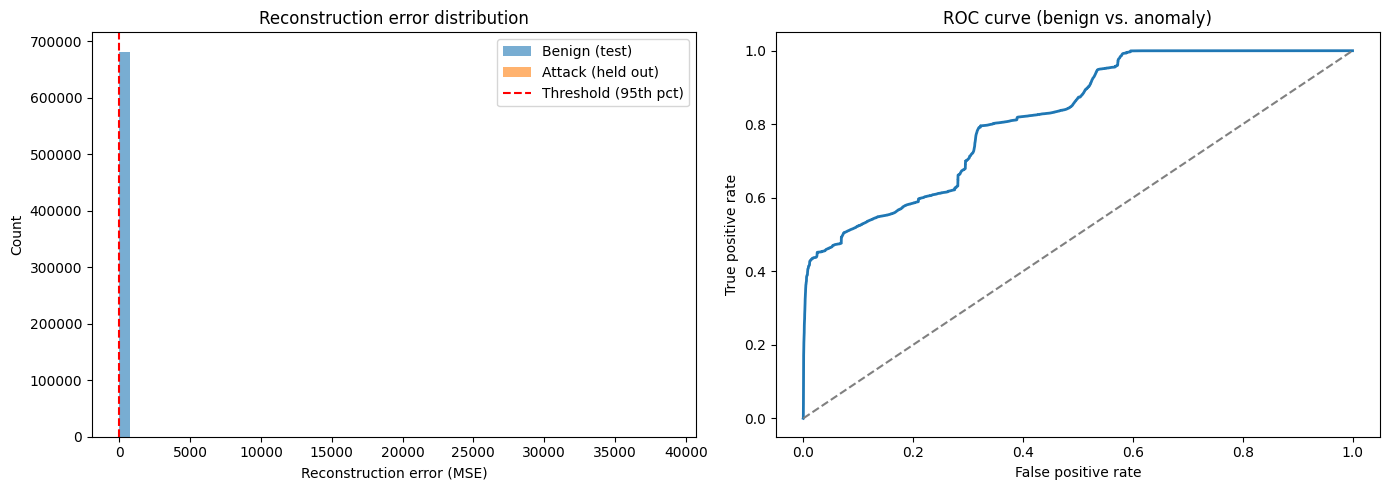

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(benign_test_errors, bins=50, alpha=0.6, label="Benign (test)")
axes[0].hist(attack_errors, bins=50, alpha=0.6, label="Attack (held out)")
axes[0].axvline(threshold, color="red", linestyle="--", label=f"Threshold ({THRESHOLD_PERCENTILE}th pct)")
axes[0].set_title("Reconstruction error distribution")
axes[0].set_xlabel("Reconstruction error (MSE)"); axes[0].set_ylabel("Count"); axes[0].legend()

fpr, tpr, _ = roc_curve(y_true, all_errors)
axes[1].plot(fpr, tpr, linewidth=2)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC curve (benign vs. anomaly)")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")

plt.tight_layout()
plt.show()


## Step 8: Save Artifacts
Saved separately from the supervised model's artifacts (different scaler, different purpose) so both can run side by side in the fusion notebook.

In [10]:
os.makedirs("models", exist_ok=True)

autoencoder.save("models/nids_autoencoder.h5")
joblib.dump(ae_scaler, "models/ae_scaler.pkl")
joblib.dump({"threshold": threshold, "feature_names": feature_names}, "models/ae_threshold.pkl")

print("Saved: models/nids_autoencoder.h5")
print("Saved: models/ae_scaler.pkl")
print("Saved: models/ae_threshold.pkl  (contains threshold + expected feature order)")


Saved: models/nids_autoencoder.h5
Saved: models/ae_scaler.pkl
Saved: models/ae_threshold.pkl  (contains threshold + expected feature order)
